In [3]:
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller

**Lodaing the Dataset**

In [4]:
df = pd.read_csv("Data/stock_data.csv", parse_dates = True, index_col = "Date")

In [5]:
df.head()

,Unnamed: 0,Open,High,Low,Close,Volume,Name
Date,,,,,,,
2006-01-03,NaN,39.69,41.22,38.79,40.91,24232729,AABA
2006-01-04,NaN,41.22,41.90,40.77,40.97,20553479,AABA
2006-01-05,NaN,40.93,41.73,40.85,41.53,12829610,AABA
2006-01-06,NaN,42.88,43.57,42.80,43.21,29422828,AABA
2006-01-09,NaN,43.10,43.66,42.82,43.42,16268338,AABA


**Cleaning of Data**

In [6]:
df.drop(columns = "Unnamed: 0", inplace = True)

In [7]:
df.head()

,Open,High,Low,Close,Volume,Name
Date,,,,,,
2006-01-03,39.69,41.22,38.79,40.91,24232729,AABA
2006-01-04,41.22,41.90,40.77,40.97,20553479,AABA
2006-01-05,40.93,41.73,40.85,41.53,12829610,AABA
2006-01-06,42.88,43.57,42.80,43.21,29422828,AABA
2006-01-09,43.10,43.66,42.82,43.42,16268338,AABA


**Ploting High Stock Price**

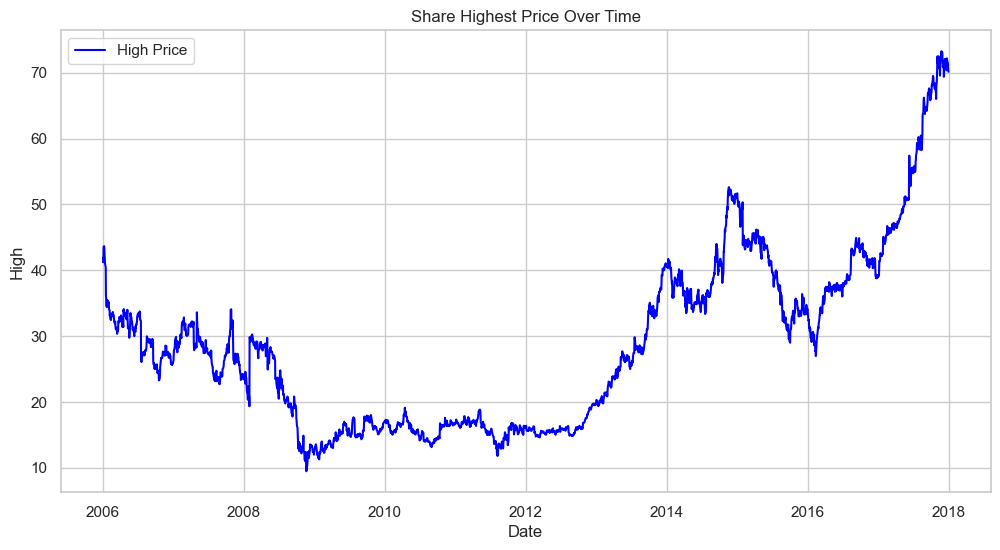

In [8]:
sns.set(style = 'whitegrid')
plt.figure(figsize = (12,6))
sns.lineplot(data=df, x='Date', y='High', label='High Price', color='blue')

plt.xlabel('Date')
plt.ylabel('High')
plt.title('Share Highest Price Over Time')
plt.show()

**Resempling Data**

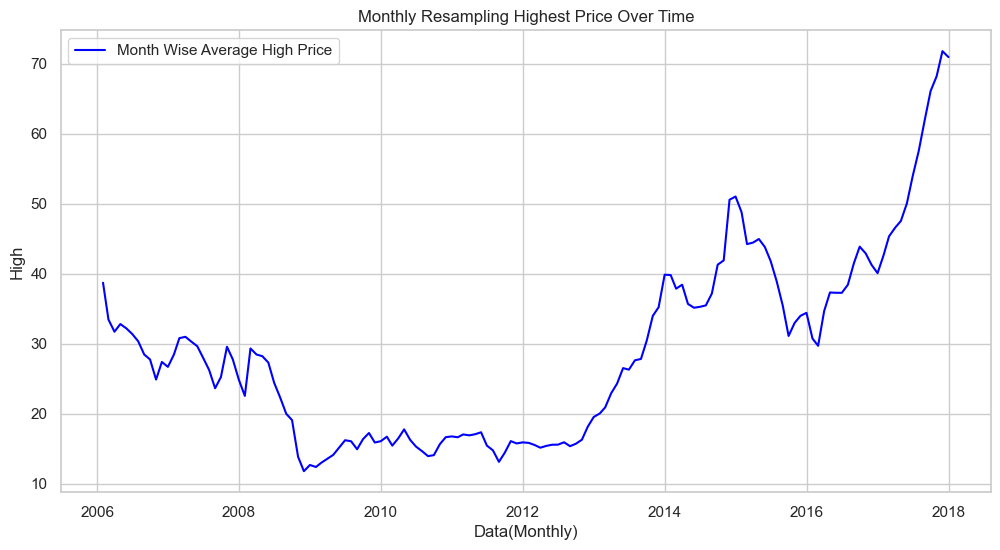

In [9]:
df_resampled = df.resample('ME').mean(numeric_only = True)

sns.set(style="whitegrid")
plt.figure(figsize=(12,6))
sns.lineplot(data = df_resampled, x=df_resampled.index, y='High', label='Month Wise Average High Price', color='blue')
plt.xlabel('Data(Monthly)')
plt.ylabel('High')
plt.title('Monthly Resampling Highest Price Over Time')
plt.show()

**Detecting Seasonality with Autocorrelation**

Date is already the index or not present int the DataFrame


<Figure size 1200x600 with 0 Axes>

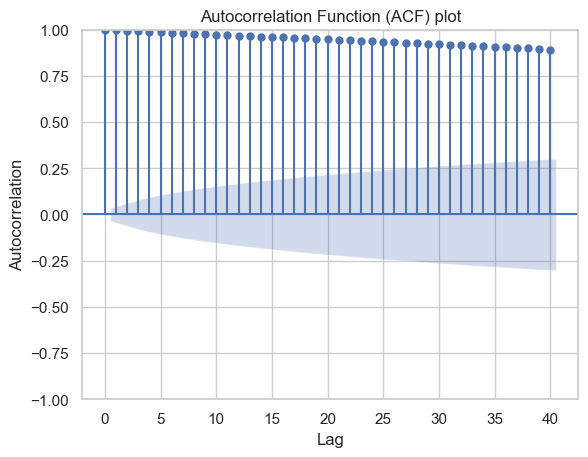

In [10]:
if 'Date' not in df.columns:
    print("Date is already the index or not present int the DataFrame")
else:
    df.set_index('Date', inplace=True)

plt.figure(figsize=(12,6))
plot_acf(df['High'], lags=40)
plt.xlabel('Lag')
plt.ylabel('Autocorrelation')
plt.title('Autocorrelation Function (ACF) plot')
plt.show()


**Testing Stationarity With ADF test**

In [15]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df['High'])
print('ADF Statistic:', result[0])
print('P-value:', result[1])
print('Critical Values:', result[4])

ADF Statistic: 0.7671404880535945
P-value: 0.9910868050318213
Critical Values: {'1%': -3.4325316347197403, '5%': -2.862503905260741, '10%': -2.5672831121111113}


**Differencing to Achieve Stationarity**

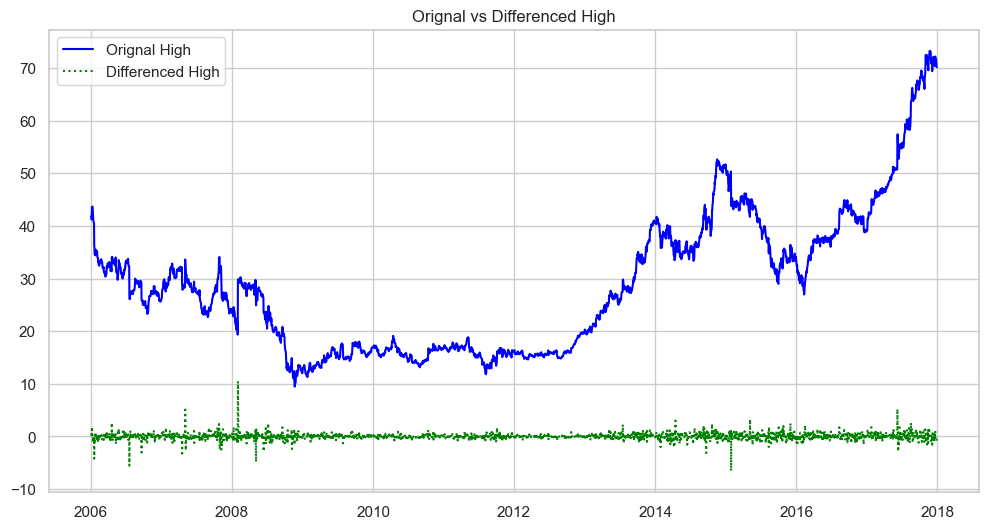

In [18]:
df['high_diff'] = df['High'].diff()
plt.figure(figsize=(12,6))
plt.plot(df['High'], label = 'Orignal High', color='blue')
plt.plot(df['high_diff'], label='Differenced High', linestyle = '--', color = 'green')
plt.legend()
plt.title('Orignal vs Differenced High')
plt.show()

**Smoothing Data with Moving Average**

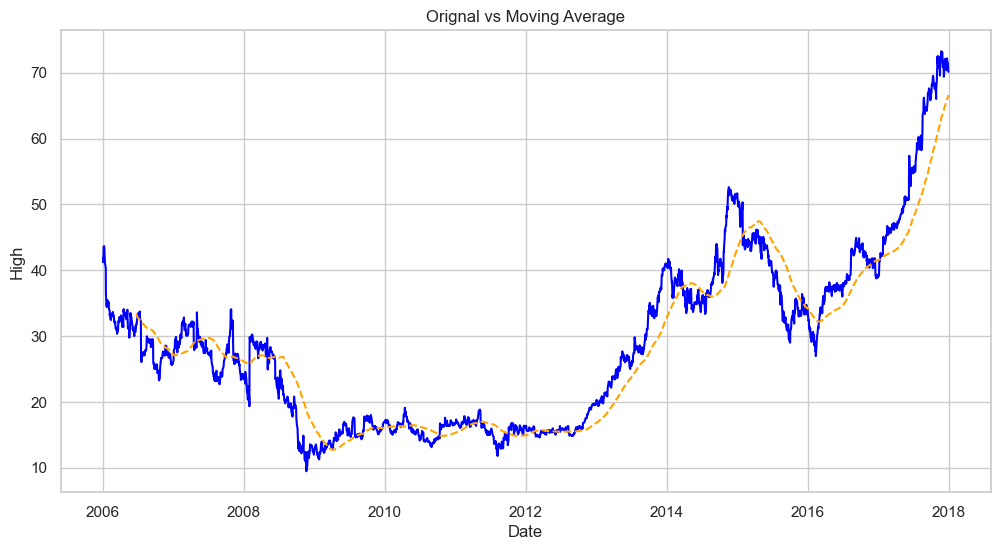

In [20]:
window_size = 120
df['high_smoothed'] = df['High'].rolling(window=window_size).mean()
plt.figure(figsize=(12,6))
plt.plot(df['High'], label= 'Orignal High', color='blue')
plt.plot(df['high_smoothed'], label=f'Moving Average (window={window_size})', linestyle='--', color='orange')
plt.xlabel('Date')
plt.ylabel('High')
plt.title('Orignal vs Moving Average')
plt.show()

**Orignal Data Vs Differenced Data**

In [23]:
df_commbined = pd.concat([df['High'], df['high_diff']], axis = 1)
print(df_commbined.head())

             High  high_diff
Date                        
2006-01-03  41.22        NaN
2006-01-04  41.90       0.68
2006-01-05  41.73      -0.17
2006-01-06  43.57       1.84
2006-01-09  43.66       0.09


In [26]:
df.dropna(subset=['high_diff'], inplace=True)
df['high_diff'].head()

Date
2006-01-04    0.68
2006-01-05   -0.17
2006-01-06    1.84
2006-01-09    0.09
2006-01-10   -0.32
Name: high_diff, dtype: float64

In [27]:
from statsmodels.tsa.stattools import adfuller
result = adfuller(df['high_diff'])
print('ADF Statstics:', result[0])
print('P-Value:',result[1])
print('Criticle Value:',result[4])

ADF Statstics: -12.14836747834325
P-Value: 1.5912766134148354e-22
Criticle Value: {'1%': -3.4325316347197403, '5%': -2.862503905260741, '10%': -2.5672831121111113}
